# Supervised machine learning - Decision Trees and Random Forests

## What will you learn in this course? 🧐🧐

This course is very practical. The goal is to help you understand the theoretical principles of decision trees. A decision tree builds a sequence of binary rules to classify observations or to make regression predictions.

You will also learn the principle of bagging, which we will illustrate by moving from Decision Tree models to Random Forest models.

* Decision Tree (regression and classification)
* Building a decision tree
     * General principle
     * Division criterion
     * Admissibility
     * Heterogeneity
         * $Y$ quantitative
         * $Y$ qualitative
     * Stopping criterion
* Fight overfitting
* General Remarks


## Decision Tree (regression and classification) 🌳🌳

Decision Trees belong to the family of recursive partitioning methods, better known by the acronym CART (_Classification And Regression Trees_). We speak of regression when the target variable is quantitative, and of classification when the target variable is qualitative (categorical). We start with Regression Trees, used when the target variable is quantitative; classification comes in a second step. A big advantage of trees is that their graphical representation is easy to read. A tree is made of three types of elements:

* The root, which contains all the training data. At the root, all training data form one undifferentiated block.
* The nodes/branches. Starting from the root, these are the points where the data is split into two subgroups. Each split uses a criterion on one of the explanatory variables, chosen to give the best possible prediction performance.
* The leaves, which are the terminal nodes of the tree. Each leaf carries a predicted value when $Y$ is quantitative, or a predicted class when $Y$ is qualitative.

So, starting from the root, we define a first node that splits the dataset according to a performance criterion, which depends on one explanatory variable and on the target variable. For each of the two branches created, we repeat the same procedure, and so on. The tree is built step by step, node by node, which splits the training data into smaller and smaller subgroups, each with its own prediction. A stopping criterion tells us when to stop creating new nodes; the final nodes are the leaves, also called terminal nodes.


decision_tree

This is an example of a decision tree: the root is at the top, the first division branches out from the root, and the sequence of branches leads down to the leaves. Decision trees are very clear and visual, which makes them easy to interpret, as long as they stay reasonably small.

## Building a decision tree 🛠🛠
### General principle

The decision tree construction algorithm works as follows (in pseudo code):

* Initialization: all the training data is assigned to the root. The root is the first node.
* For each node, we try to make a division:
    * We select an explanatory variable $X$ and define a cutoff criterion: a threshold if $X$ is quantitative, or a split into groups of modalities if $X$ is qualitative. In theory, every possible division of every explanatory variable is tested, and the algorithm selects the one that minimizes an error measure (we will look at it in detail later in the lesson). (Note that in scikit-learn only quantitative variables may be used, so the cutoff is always a threshold.)
    * The node is marked as terminal if no admissible division can be found (we will explain this in detail later in the lesson).
* The construction stops when all nodes are terminal. A predicted value or class is then assigned to each terminal node; we will see how below.

To complete this algorithm, we need three things:

1. A criterion for selecting the best division.
2. A set of rules to decide whether a division is admissible, and therefore when to create terminal nodes.
3. A method for assigning a value or class to each terminal node, or leaf.

### Division criterion

#### Admissibility

A division is **admissible** if both resulting child nodes are non-empty (i.e. at least one observation belongs to each child node). For a parent node containing $M$ observations, there are at most $M - 1$ possible divisions if the variable selected for the division is quantitative or qualitative ordinal, and at most $2^{M-1}-1$ admissible divisions if the selected variable is nominal. However, as mentioned above, scikit-learn only accepts quantitative variables, so all qualitative variables have to be converted to a numerical format.

#### Heterogeneity
To select the best admissible division, we define a **heterogeneity** function, which has two properties:

* It equals zero when all observations in a node belong to the same modality of $Y$ (classification), or have the same value of $Y$ (regression).
* It is maximal when the values of $Y$ are uniformly distributed in the node.

We then look for the division that minimizes the sum of the heterogeneities of the child nodes. Below, we define one heterogeneity function for regression and another one for classification.

#### $Y$ quantitative

In the case of regression, the heterogeneity of node $k$ is written as follows:

$$
H_k=\frac{1}{Card(k)}\cdot\sum_{i\in{k}}(y_i-\underline{y_k})^2
$$

$Card(k)$, also written $|k|$, is the number of elements in node $k$, and $\underline{y_k}$ is the mean of $Y$ over the observations of node $k$. In other words, $H_k$ is the variance of $Y$ in node $k$.
The division retained is the one for which $\frac{Card(k_G)}{Card(k)}H_{k_G}+\frac{Card(k_D)}{Card(k)}H_{k_D}$, the sum of the heterogeneities of the left branch and the right branch weighted by their sizes, is minimal.
Let's stop for a moment and think about this criterion. We are looking for the division that minimizes the sum of the variances of $Y$ in the left and right branches. The lower the variance of $Y$ in each branch, the more similar the observations within each branch are in terms of the target variable. If a model can put observations with similar values of $Y$ in the same branch, there is a good chance that it will be a good predictor!

#### $Y$ qualitative

Let $Y$ be a qualitative variable with $m$ modalities, or categories, numbered from 1 to $m$. The heterogeneity function used most of the time is the GINI concentration (or Gini impurity):

$$
H_k=\sum_{i=1}^{m}p_{k}^{i}\cdot(1-p_{k}^{i})
$$

where $p_{k}^{i}$ is the proportion of class $i$ of $Y$ in node $k$. Let's analyze this formula. What happens when all observations in a branch belong to the same modality $y_j$ of $Y$? Then $p_{i}=0 \forall i \neq j$ and $1 - p_{j} = 0$, so the heterogeneity is 0. The formula reaches its maximum value when the values of $Y$ are uniformly distributed in the branch. Again, we try to minimize the sum of the heterogeneities of the branches. So the deeper we go into the tree, the more homogeneous the branches become: more and more observations in each node belong to the same class of $Y$.

### Stopping criterion

A given node is terminal in the following cases:
* when it is homogeneous, i.e. when all observations in the node have the same value or the same modality of $Y$;
* when there are no more admissible divisions;
* when the number of observations in the node is below a predefined value, usually a few units (in scikit-learn, this corresponds to the `min_samples_split` and `min_samples_leaf` arguments);
* when the tree reaches a certain depth (a certain number of successive divisions).

## Fight overfitting 👮👮

We saw earlier, with the LASSO and RIDGE models, that overfitting is a major risk in any supervised learning problem. For trees, the stopping criterion is key to limiting overfitting. With a very loose stopping criterion, the tree can grow to its fullest: terminal nodes will contain very few observations, and $Y$ will most probably be perfectly homogeneous in each of them. Such a tree will most likely get a near-perfect score on the training data, because it has fitted every single training observation.

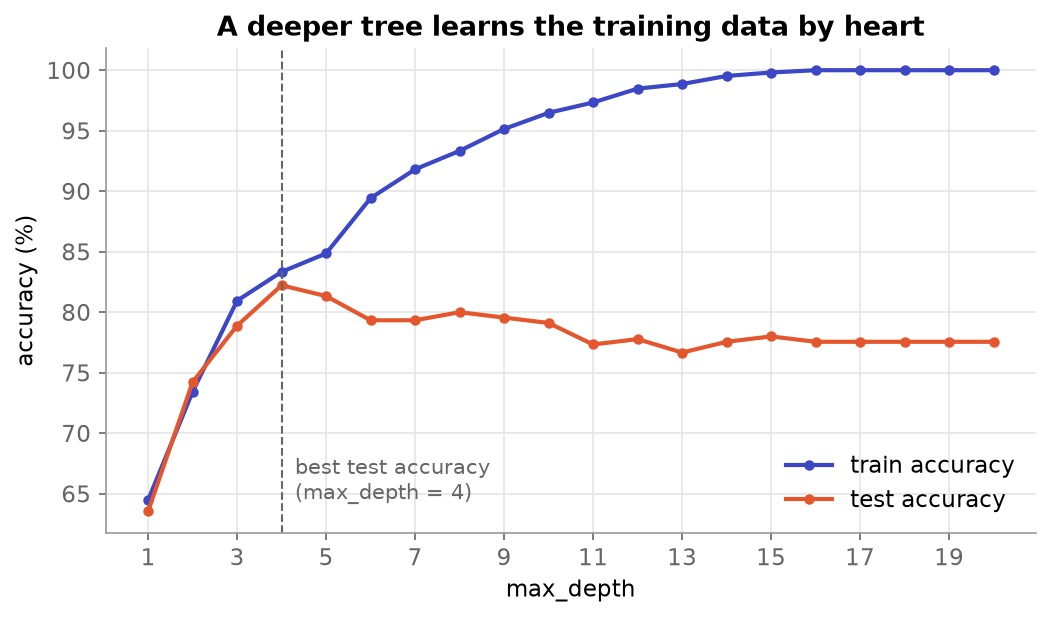

In the figure above (a simulated dataset), the training accuracy keeps rising with the depth until it reaches 100%, while the test accuracy peaks at a small depth and then drops: the deeper tree is learning the noise of the training data.

 However, this only works well when the test observations are almost identical to the training examples. Any slight difference in the distribution of the variables in the test set can give very unpredictable results: sometimes good, but most likely incorrect. This is because we let the bias drop to zero and the variance go through the roof, which gives a model that will most likely generalize poorly to new data.

The goal is to find an intermediate tree that gives a better bias/variance trade-off for estimating $Y$. Unfortunately, the number of possible sub-trees is often very large, and checking the performance of every one of them would take a long time.

Instead, you can tune the stopping criteria with a grid search, to find the hyperparameters that maximize the prediction performance on data not used for training (cross-validation).

Reminder: the stopping criteria you can tune to reach a good bias/variance trade-off are:
* `min_samples_leaf`
* `min_samples_split`
* `max_depth`

## General remarks

* The algorithm tends to pay less attention to qualitative variables when they are converted into dummy variables. This is because the explanatory power of the variable is split over as many variables as there are modalities. A common strategy is to group rare modalities together, or modalities whose observations have a similar distribution of $Y$.

* Decision trees do not require special assumptions about the distributions of the variables (no normalization needed).

* Since a single variable is selected to create each node, the model performs an implicit variable selection. However, because only one variable is used for each split, less informative variables might not be included in the model, and only part of the information in the data will be used.

* The search for a division depends only on the order of the values of the quantitative explanatory variables, not on the values themselves. So the algorithm is robust to outliers and to skewed (asymmetric) distributions.

* Because of the hierarchical structure of the tree (divisions are made one by one), an error made at one division propagates to all the child nodes below it. Decision trees can therefore miss the global optimum, and so miss the true classification or regression function that links the explanatory variables to the target variable.

* In the case of regression, the tree gives a step function: all observations in the same leaf get the same estimated value of $Y$.

* If the true function is regular or smooth (for example a polynomial or a straight line), the decision tree model will not reproduce these properties.